# Clasificar el tipo de bosque a partir del terreno — Covertype

**El encargo.** Dada la ficha cartográfica de una parcela de 30×30 metros (altitud, pendiente, distancias al agua, a carreteras y a puntos de incendio, sombreado, área silvestre y tipo de suelo), decidir qué especie de bosque crece encima.

**Por qué este dataset.** *Covertype* (UCI, Blackard & Dean, 1998) recoge mediciones reales del Servicio Forestal de EE. UU. y del USGS en el *Roosevelt National Forest* (Colorado): **581.012 parcelas**, 54 variables y 7 clases de cobertura. Es un problema **multiclase con desbalance real**, que permite trabajar todo lo que pide el enunciado: preparación, desbalance, métricas por clase, matriz de confusión e importancia de variables. Y como es un *benchmark* clásico, los números son comparables con los de la literatura.

**Recorrido**

| Bloque | Contenido |
|---|---|
| 1 | De dónde salen los datos |
| 2 | Qué se predice y con qué se predice |
| 3 | Reconocer el terreno (EDA) |
| 4 | Dejar los datos en condiciones |
| 5 | Partir en dos: entrenamiento y prueba |
| 6 | Los modelos candidatos y el elegido |
| 7 | Medir: accuracy, precision, recall, F1 y matriz de confusión |
| 8 | Qué variables manda |
| 9 | Lectura crítica de los resultados |


## 1. De dónde salen los datos

El notebook funciona igual en **Google Colab** que en local. En Colab casi todas las librerías ya vienen instaladas, así que la primera celda solo interviene si falta algo.

El dataset se baja con `sklearn.datasets.fetch_covtype`, que lo obtiene del repositorio de la UCI **sin ninguna autenticación** (unos 11 MB comprimidos). La primera vez tarda unos segundos; después queda en la caché local de scikit-learn.


In [1]:
# Instalación (solo instala si falta algo; en Colab normalmente no hace nada)
import importlib, subprocess, sys

EN_COLAB = "google.colab" in sys.modules
print("¿Ejecutando en Google Colab?", EN_COLAB)

for paquete in ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn"]:
    modulo = "sklearn" if paquete == "scikit-learn" else paquete
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
SEMILLA = 42                     # semilla para reproducibilidad
np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.1.1


In [3]:
# Descarga del dataset (sin autenticación). La primera vez tarda unos segundos.
inicio = time.time()
datos = fetch_covtype(as_frame=True)
df = datos.frame.copy()
print(f"Descargado/cargado en {time.time() - inicio:.1f} s")
print("Dimensiones:", df.shape)
df.head()

Descargado/cargado en 0.2 s
Dimensiones: (581012, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Cover_Type
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5


## 2. Qué se intenta adivinar

- **Tipo de problema:** clasificación supervisada **multiclase** (7 clases).
- **Pregunta de negocio:** dadas las características cartográficas de una parcela, ¿qué tipo de bosque hay en ella? Sirve para inventariar zonas remotas sin enviar personal de campo.

**Variable objetivo (`Cover_Type`)**, especie dominante:

| Código | Tipo de cobertura |
|---|---|
| 1 | Spruce/Fir (Pícea/Abeto) |
| 2 | Lodgepole Pine (Pino contorta) |
| 3 | Ponderosa Pine (Pino ponderosa) |
| 4 | Cottonwood/Willow (Álamo/Sauce) |
| 5 | Aspen (Álamo temblón) |
| 6 | Douglas-fir (Abeto de Douglas) |
| 7 | Krummholz |

**Variables de entrada (54):**

| Variable | Tipo | Descripción |
|---|---|---|
| `Elevation` | numérica | Altitud (m) |
| `Aspect` | numérica | Orientación (grados azimut) |
| `Slope` | numérica | Pendiente (grados) |
| `Horizontal_Distance_To_Hydrology` | numérica | Distancia horizontal al agua más cercana (m) |
| `Vertical_Distance_To_Hydrology` | numérica | Distancia vertical al agua (m, puede ser negativa) |
| `Horizontal_Distance_To_Roadways` | numérica | Distancia a la carretera más cercana (m) |
| `Hillshade_9am`, `Hillshade_Noon`, `Hillshade_3pm` | numérica | Índice de sombreado (0-255) |
| `Horizontal_Distance_To_Fire_Points` | numérica | Distancia a puntos de ignición de incendios (m) |
| `Wilderness_Area_0..3` | binaria (one-hot) | 4 áreas silvestres |
| `Soil_Type_0..39` | binaria (one-hot) | 40 tipos de suelo |


In [4]:
NOMBRES_CLASE = {1: "Pícea/Abeto", 2: "Pino contorta", 3: "Pino ponderosa",
                 4: "Álamo/Sauce", 5: "Álamo temblón", 6: "Abeto Douglas", 7: "Krummholz"}
OBJETIVO = "Cover_Type"
X = df.drop(columns=OBJETIVO)
y = df[OBJETIVO].astype(int)

cols_num = X.columns[:10].tolist()                                      # 10 numéricas continuas
cols_wild = [c for c in X.columns if c.startswith("Wilderness_Area")]   # 4 binarias
cols_soil = [c for c in X.columns if c.startswith("Soil_Type")]         # 40 binarias
print(f"Numéricas: {len(cols_num)} | Wilderness (one-hot): {len(cols_wild)} | Soil (one-hot): {len(cols_soil)}")
df.info(verbose=False)

Numéricas: 10 | Wilderness (one-hot): 4 | Soil (one-hot): 40
<class 'pandas.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Columns: 55 entries, Elevation to Cover_Type
dtypes: float64(54), int32(1)
memory usage: 241.6 MB


## 3. Reconocer el terreno


In [5]:
# Estadística descriptiva de las variables numéricas
df[cols_num].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.4,280.0,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.7,111.9,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.1,7.5,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.4,212.5,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.4,58.3,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.1,1559.3,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.1,26.8,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.3,19.8,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.5,38.3,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.3,1324.2,0.0,1024.0,1710.0,2550.0,7173.0


,clase,registros,porcentaje_%
Cover_Type,,,
1,Pícea/Abeto,211840,36.46
2,Pino contorta,283301,48.76
3,Pino ponderosa,35754,6.15
4,Álamo/Sauce,2747,0.47
5,Álamo temblón,9493,1.63
6,Abeto Douglas,17367,2.99
7,Krummholz,20510,3.53


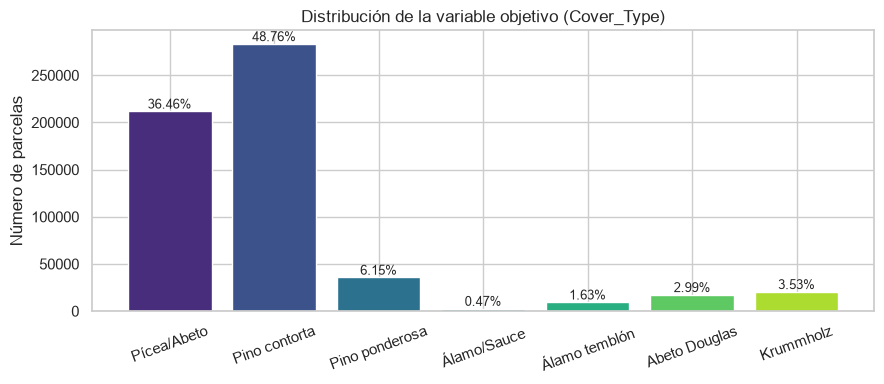

Ratio clase mayoritaria / minoritaria: 103 : 1


In [6]:
# Distribución de la variable objetivo -> evidencia el DESBALANCE
conteo = y.value_counts().sort_index()
pct = (conteo / len(y) * 100).round(2)
display(pd.DataFrame({"clase": [NOMBRES_CLASE[i] for i in conteo.index],
                      "registros": conteo.values, "porcentaje_%": pct.values}, index=conteo.index))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar([NOMBRES_CLASE[i] for i in conteo.index], conteo.values, color=sns.color_palette("viridis", 7))
for i, (c, p) in enumerate(zip(conteo.values, pct.values)):
    ax.text(i, c, f"{p}%", ha="center", va="bottom", fontsize=9)
ax.set_title("Distribución de la variable objetivo (Cover_Type)")
ax.set_ylabel("Número de parcelas")
plt.xticks(rotation=20)
plt.tight_layout(); plt.show()
print(f"Ratio clase mayoritaria / minoritaria: {conteo.max() / conteo.min():.0f} : 1")

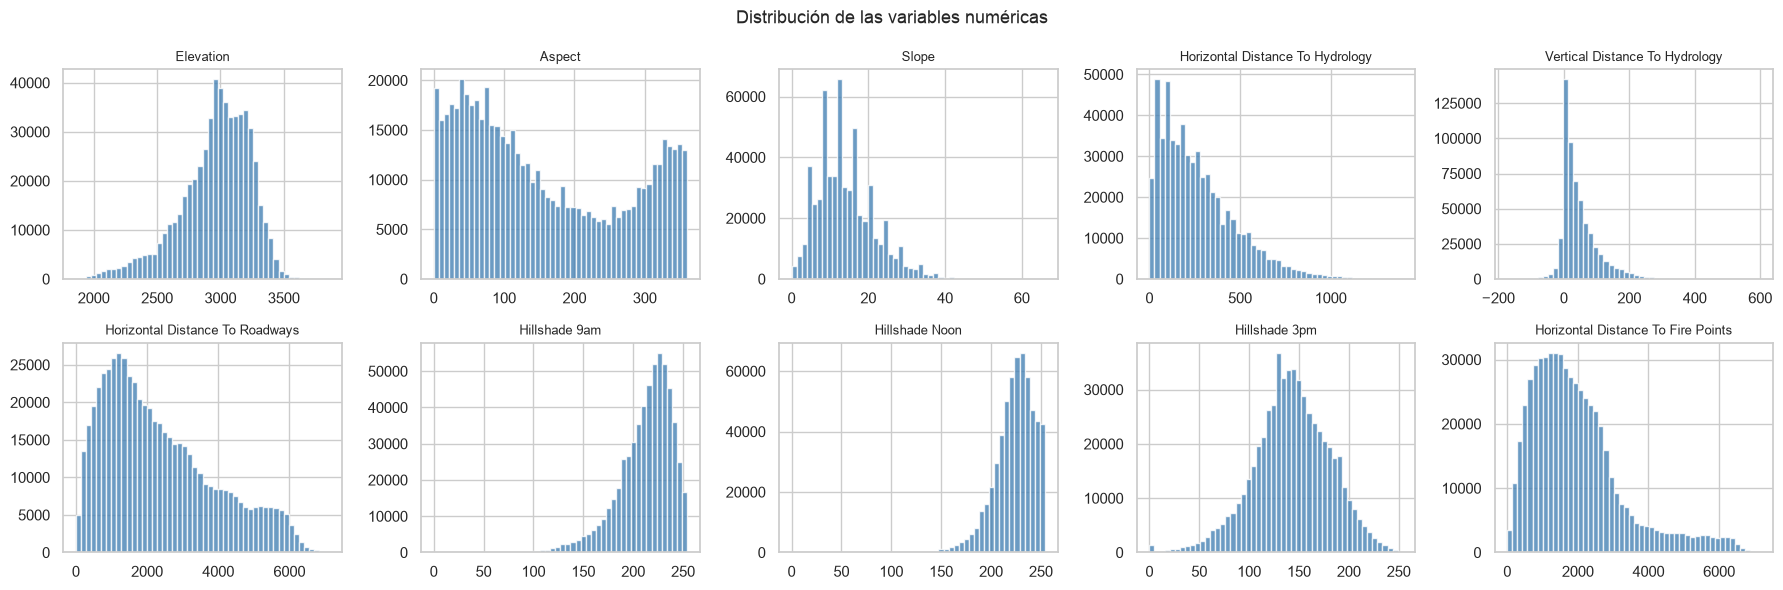

In [7]:
# Histogramas de las variables numéricas
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, col in zip(axes.ravel(), cols_num):
    ax.hist(df[col], bins=50, color="steelblue", alpha=0.8)
    ax.set_title(col.replace("_", " "), fontsize=9)
plt.suptitle("Distribución de las variables numéricas", fontsize=13)
plt.tight_layout(); plt.show()

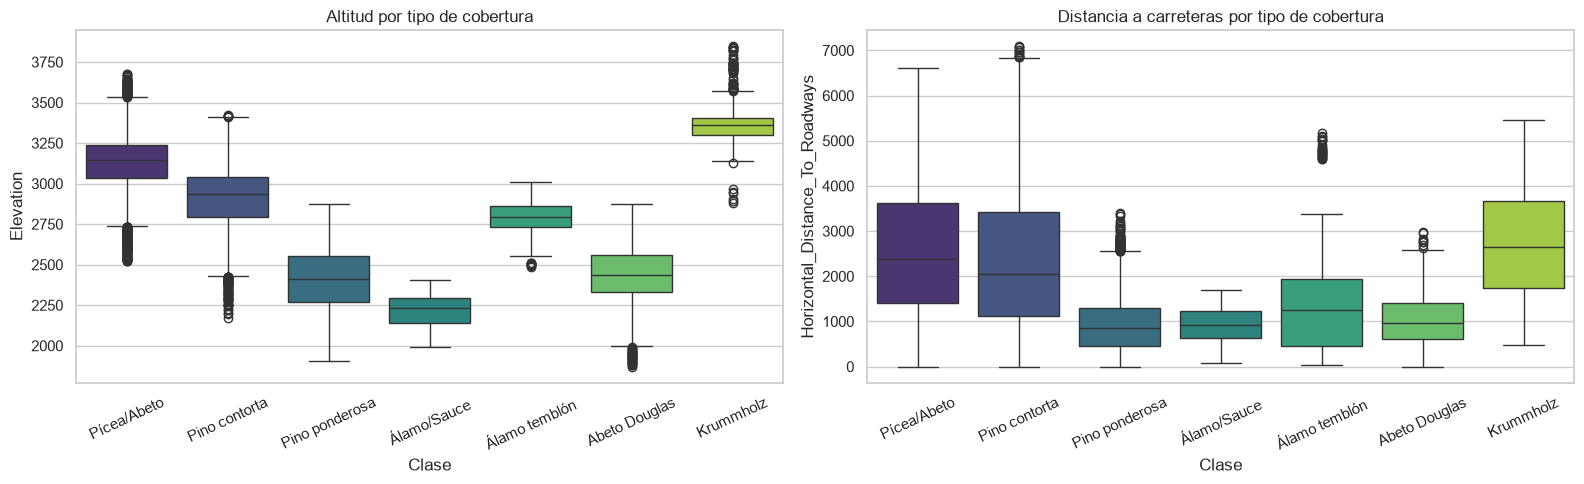

In [8]:
# Altitud por tipo de cobertura (la variable más discriminante, como se verá)
muestra = df.sample(50_000, random_state=SEMILLA)
muestra["Clase"] = muestra[OBJETIVO].map(NOMBRES_CLASE)
orden = [NOMBRES_CLASE[i] for i in range(1, 8)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=muestra, x="Clase", y="Elevation", hue="Clase", hue_order=orden,
            order=orden, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Altitud por tipo de cobertura"); axes[0].tick_params(axis="x", rotation=25)
sns.boxplot(data=muestra, x="Clase", y="Horizontal_Distance_To_Roadways", hue="Clase",
            hue_order=orden, order=orden, palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Distancia a carreteras por tipo de cobertura"); axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

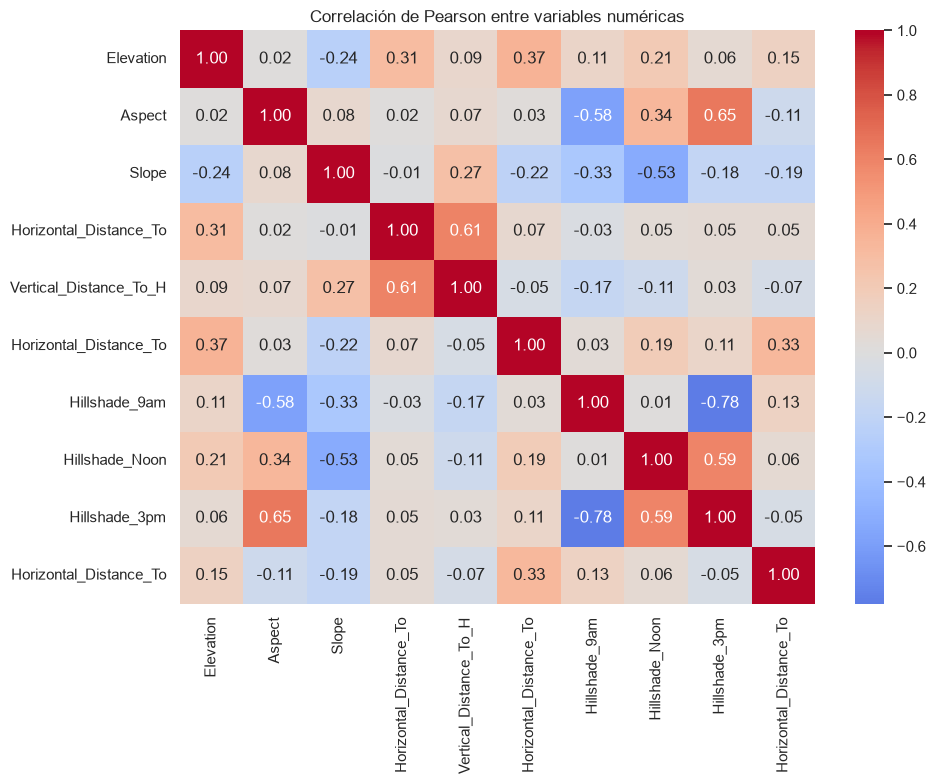

In [9]:
# Matriz de correlación entre variables numéricas
plt.figure(figsize=(10, 8))
corr = df[cols_num].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            xticklabels=[c[:22] for c in cols_num], yticklabels=[c[:22] for c in cols_num])
plt.title("Correlación de Pearson entre variables numéricas")
plt.tight_layout(); plt.show()

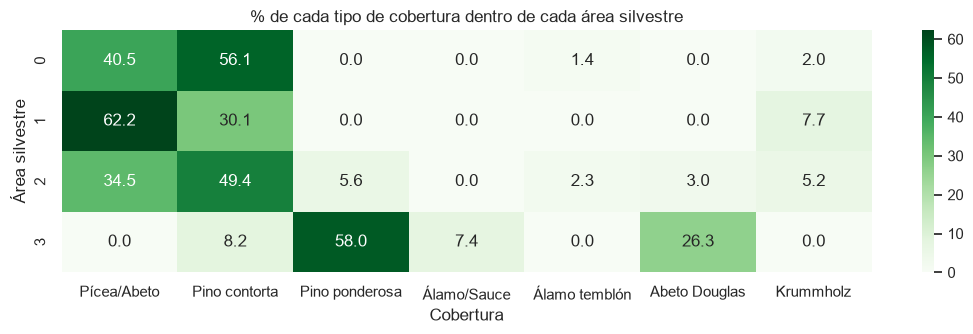

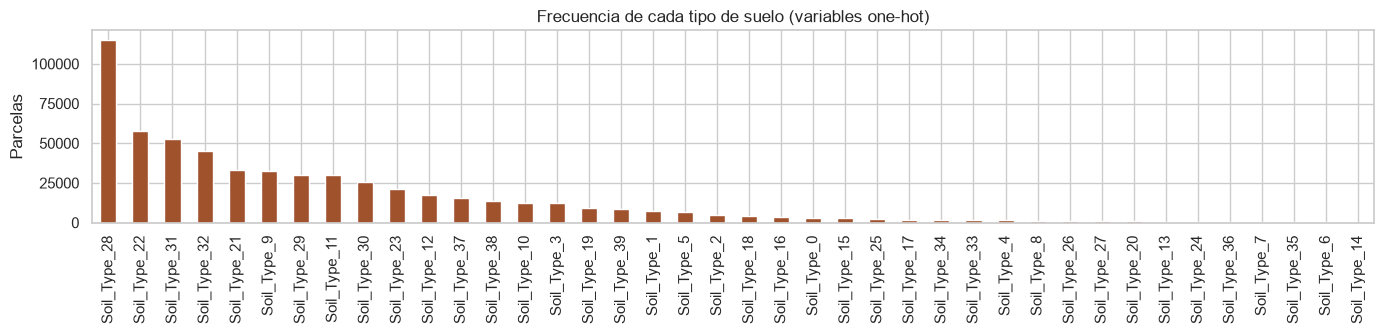

In [10]:
# Variables categóricas (one-hot): área silvestre vs tipo de cobertura
area = X[cols_wild].values.argmax(axis=1)
tabla = pd.crosstab(pd.Series(area, name="Área silvestre"), y.map(NOMBRES_CLASE).rename("Cobertura"), normalize="index") * 100
plt.figure(figsize=(11, 3.5))
sns.heatmap(tabla[orden], annot=True, fmt=".1f", cmap="Greens")
plt.title("% de cada tipo de cobertura dentro de cada área silvestre")
plt.tight_layout(); plt.show()

suelo_freq = X[cols_soil].sum().sort_values(ascending=False)
plt.figure(figsize=(14, 3.5))
suelo_freq.plot(kind="bar", color="sienna")
plt.title("Frecuencia de cada tipo de suelo (variables one-hot)"); plt.ylabel("Parcelas")
plt.tight_layout(); plt.show()

**Lo que revela la exploración**

- **Desbalance fuerte:** *Pícea/Abeto* (36,5 %) y *Pino contorta* (48,8 %) concentran casi el 85 % de los datos, mientras *Álamo/Sauce* se queda en el 0,5 %. El ratio entre la clase mayoritaria y la minoritaria es de **103 a 1**, lo que obliga a usar división estratificada y a mirar métricas **macro**, no solo la accuracy.
- **La altitud (`Elevation`) separa muy bien las clases:** Krummholz y Pícea/Abeto viven en zonas altas; Pino ponderosa, Álamo/Sauce y Abeto Douglas en zonas bajas.
- El **área silvestre** también es muy informativa (el área 3 concentra casi todo el Pino ponderosa y el Álamo/Sauce).
- Las variables de sombreado están correlacionadas entre sí (`Hillshade_9am` vs `Hillshade_3pm` ≈ 0,78) y las distancias horizontal y vertical al agua ≈ 0,61. Para modelos de árboles no es un problema.
- Varias distribuciones son **asimétricas** (las distancias), algo que no afecta a los modelos basados en árboles.


## 4. Dejar los datos en condiciones


In [11]:
# 4.1 Valores nulos
nulos = df.isnull().sum()
print("Total de valores nulos:", int(nulos.sum()))

# 4.2 Duplicados
dup = df.duplicated().sum()
print("Filas duplicadas:", int(dup))

# 4.3 Coherencia de las variables one-hot: cada fila debe tener exactamente 1 área y 1 tipo de suelo
print("Filas con exactamente 1 área silvestre:", int((X[cols_wild].sum(axis=1) == 1).sum()), "de", len(X))
print("Filas con exactamente 1 tipo de suelo:  ", int((X[cols_soil].sum(axis=1) == 1).sum()), "de", len(X))

# 4.4 Rangos válidos (sombreado entre 0 y 255, pendiente y orientación no negativas)
print("Hillshade fuera de [0,255]:", int(((df[["Hillshade_9am","Hillshade_Noon","Hillshade_3pm"]] < 0) |
                                          (df[["Hillshade_9am","Hillshade_Noon","Hillshade_3pm"]] > 255)).sum().sum()))

# 4.5 Columnas constantes (sin información)
constantes = [c for c in X.columns if X[c].nunique() <= 1]
print("Columnas constantes:", constantes)

Total de valores nulos: 0


Filas duplicadas: 0
Filas con exactamente 1 área silvestre: 581012 de 581012
Filas con exactamente 1 tipo de suelo:   581012 de 581012
Hillshade fuera de [0,255]: 0


Columnas constantes: []


In [12]:
# Si existieran duplicados o nulos se tratarían así (aquí no cambia nada, pero deja el pipeline robusto):
df_limpio = df.drop_duplicates().dropna()
X = df_limpio.drop(columns=OBJETIVO).astype("float32")   # float32 para reducir memoria
y = df_limpio[OBJETIVO].astype(int)
print("Dimensiones finales:", X.shape, "| memoria X:", round(X.memory_usage().sum() / 1e6, 1), "MB")

Dimensiones finales: (581012, 54) | memoria X: 125.5 MB


| Aspecto | Lo que se encontró | Decisión |
|---|---|---|
| Nulos | 0 | No hace falta imputación. |
| Duplicados | 0 | No se elimina nada (el código lo haría si los hubiera). |
| Variables categóricas | `Wilderness_Area` (4) y `Soil_Type` (40) ya vienen **codificadas one-hot** y son coherentes (exactamente un 1 por fila) | Se usan tal cual; no hace falta `OneHotEncoder`. |
| Desbalance | Ratio ≈ 103:1 | (1) `train_test_split` **estratificado**; (2) se reportan métricas **macro** y por clase; (3) se prueba `class_weight` en el modelo. No se usa sobremuestreo (SMOTE) porque con 465k registros de entrenamiento todas las clases tienen ≥2.000 ejemplos y los árboles las aprenden bien. |
| Escalado | Magnitudes muy distintas (pendiente 0-66 frente a distancias 0-7.000) | **Solo se escala para la Regresión Logística** (baseline sensible a la escala), con `StandardScaler` **dentro de un Pipeline** ajustado solo con train, para evitar *data leakage*. Los modelos de árboles son invariantes a transformaciones monótonas, así que no se escalan. |


## 5. Partir en dos: entrenamiento y prueba


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)

print(f"Train: {X_train.shape[0]:,} registros | Test: {X_test.shape[0]:,} registros")
comparacion = pd.DataFrame({"% total": y.value_counts(normalize=True).sort_index() * 100,
                            "% train": y_train.value_counts(normalize=True).sort_index() * 100,
                            "% test":  y_test.value_counts(normalize=True).sort_index() * 100}).round(2)
comparacion.index = [NOMBRES_CLASE[i] for i in comparacion.index]
comparacion

Train: 464,809 registros | Test: 116,203 registros


,% total,% train,% test
Pícea/Abeto,36.46,36.46,36.46
Pino contorta,48.76,48.76,48.76
Pino ponderosa,6.15,6.15,6.15
Álamo/Sauce,0.47,0.47,0.47
Álamo temblón,1.63,1.63,1.63
Abeto Douglas,2.99,2.99,2.99
Krummholz,3.53,3.53,3.53


La proporción de cada clase es idéntica en train y test gracias a `stratify=y`, por lo que la evaluación es representativa incluso para las clases minoritarias. Se reserva un 20 % (≈116k registros) como **conjunto de prueba** que el modelo no ve durante el entrenamiento.

## 6. Los modelos candidatos

### 6.1 Por qué estos modelos y no otros

Se comparan cuatro modelos (ninguno es Regresión Lineal):

1. **Dummy (clase más frecuente)** – *baseline* trivial: marca el piso mínimo que cualquier modelo debe superar.
2. **Regresión Logística multinomial** (con escalado) – *baseline* lineal: mide cuánto se gana al capturar relaciones **no lineales**.
3. **HistGradientBoosting** – *boosting* por histogramas, muy rápido en datasets grandes.
4. **Random Forest** – **modelo principal propuesto**.

**¿Por qué Random Forest como modelo principal?**
- Las fronteras entre clases son **no lineales** e involucran **interacciones** (por ejemplo, la misma altitud implica especies distintas según el área silvestre y el tipo de suelo); los árboles las modelan de forma natural.
- Maneja sin problema la mezcla de variables continuas y 44 binarias, **no requiere escalado** y es robusto a outliers y a distribuciones asimétricas.
- El *bagging* (promedio de cientos de árboles profundos entrenados con muestras bootstrap) reduce la varianza y el sobreajuste de un árbol individual.
- Con muchos datos (465k filas) los árboles profundos pueden memorizar patrones locales finos (zonas geográficas), algo que favorece especialmente a RF en Covertype.
- Ofrece **importancia de variables**, lo que aporta interpretabilidad.
- Se paraleliza en todos los núcleos (`n_jobs=-1`).


In [14]:
def evaluar(nombre, modelo, X_tr, y_tr, X_te, y_te):
    # Entrena el modelo, predice sobre test y devuelve las métricas principales
    t0 = time.time()
    modelo.fit(X_tr, y_tr)
    t_fit = time.time() - t0
    pred = modelo.predict(X_te)
    return {
        "modelo": nombre,
        "accuracy": accuracy_score(y_te, pred),
        "precision_macro": precision_score(y_te, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_te, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_te, pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_te, pred, average="weighted", zero_division=0),
        "tiempo_entrenamiento_s": round(t_fit, 1),
    }, pred

modelos = {
    "Dummy (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
    "Regresión Logística (escalada)": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=300, random_state=SEMILLA)),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.1, max_leaf_nodes=63, early_stopping=False, random_state=SEMILLA),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, n_jobs=-1, random_state=SEMILLA),
}

resultados, predicciones = [], {}
for nombre, modelo in modelos.items():
    res, pred = evaluar(nombre, modelo, X_train, y_train, X_test, y_test)
    resultados.append(res); predicciones[nombre] = pred
    print(f"{nombre:32s} accuracy={res['accuracy']:.4f}  f1_macro={res['f1_macro']:.4f}  ({res['tiempo_entrenamiento_s']} s)")

tabla_resultados = pd.DataFrame(resultados).set_index("modelo").round(4)
tabla_resultados

Dummy (clase mayoritaria)        accuracy=0.4876  f1_macro=0.0937  (0.0 s)


Regresión Logística (escalada)   accuracy=0.7235  f1_macro=0.5304  (7.2 s)


HistGradientBoosting             accuracy=0.8850  f1_macro=0.8384  (62.3 s)


Random Forest                    accuracy=0.9548  f1_macro=0.9250  (15.1 s)


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,tiempo_entrenamiento_s
modelo,,,,,,
Dummy (clase mayoritaria),0.4876,0.0697,0.1429,0.0937,0.3197,0.0
Regresión Logística (escalada),0.7235,0.5913,0.5095,0.5304,0.7139,7.2
HistGradientBoosting,0.8850,0.8343,0.8439,0.8384,0.8849,62.3
Random Forest,0.9548,0.9459,0.9071,0.9250,0.9545,15.1


### 6.2 Otra forma de atacar el desbalance

Se entrena una variante de Random Forest con `class_weight="balanced_subsample"`, que pondera cada clase de forma inversamente proporcional a su frecuencia en cada muestra bootstrap. La idea es comprobar si penalizar más los errores en las clases minoritarias mejora su *recall*.


In [15]:
rf_bal = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=SEMILLA,
                                class_weight="balanced_subsample")
res, pred = evaluar("Random Forest (balanced)", rf_bal, X_train, y_train, X_test, y_test)
resultados.append(res); predicciones["Random Forest (balanced)"] = pred
tabla_resultados = pd.DataFrame(resultados).set_index("modelo").round(4)
tabla_resultados

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,tiempo_entrenamiento_s
modelo,,,,,,
Dummy (clase mayoritaria),0.4876,0.0697,0.1429,0.0937,0.3197,0.0
Regresión Logística (escalada),0.7235,0.5913,0.5095,0.5304,0.7139,7.2
HistGradientBoosting,0.8850,0.8343,0.8439,0.8384,0.8849,62.3
Random Forest,0.9548,0.9459,0.9071,0.9250,0.9545,15.1
Random Forest (balanced),0.9553,0.9449,0.9069,0.9246,0.9551,15.5


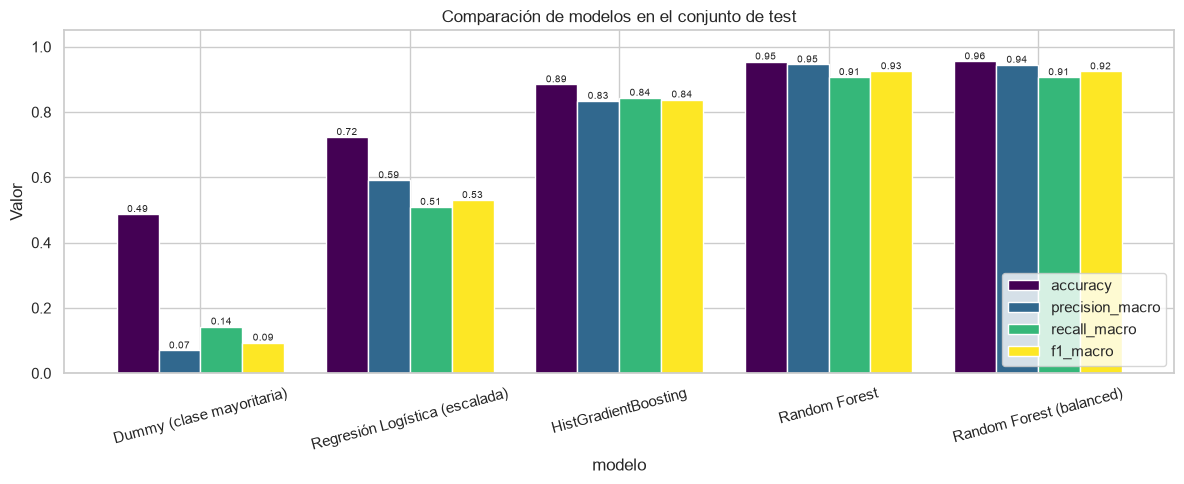

In [16]:
# Comparación gráfica de modelos
metricas_plot = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
ax = tabla_resultados[metricas_plot].plot(kind="bar", figsize=(12, 5), colormap="viridis", width=0.8)
ax.set_title("Comparación de modelos en el conjunto de test"); ax.set_ylabel("Valor"); ax.set_ylim(0, 1.05)
ax.legend(loc="lower right"); plt.xticks(rotation=15)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.show()

In [17]:
# Selección del modelo final según F1 macro (métrica más exigente con el desbalance)
mejor_nombre = tabla_resultados.drop(index="Dummy (clase mayoritaria)")["f1_macro"].idxmax()
modelo_final = rf_bal if mejor_nombre == "Random Forest (balanced)" else modelos[mejor_nombre]
y_pred = predicciones[mejor_nombre]
print("Modelo seleccionado:", mejor_nombre)

Modelo seleccionado: Random Forest


## 7. Medir el modelo

### 7.1 Accuracy, Precision, Recall y F1-Score

- **Accuracy**: proporción total de predicciones correctas.
- **Precision** (por clase): de las parcelas que el modelo etiquetó como clase *k*, ¿qué fracción realmente lo es? Penaliza los **falsos positivos**.
- **Recall** (por clase): de las parcelas que realmente son clase *k*, ¿qué fracción detectó el modelo? Penaliza los **falsos negativos**.
- **F1-Score**: media armónica de precision y recall; solo es alta si las dos lo son.
- **Promedio macro**: media simple entre clases (todas pesan igual, así que refleja el desempenho en las minoritarias). **Promedio ponderado**: pondera por el número de ejemplos de cada clase.


In [18]:
metricas_finales = pd.DataFrame({
    "Accuracy":  [accuracy_score(y_test, y_pred)] * 2,
    "Precision": [precision_score(y_test, y_pred, average="macro"), precision_score(y_test, y_pred, average="weighted")],
    "Recall":    [recall_score(y_test, y_pred, average="macro"),    recall_score(y_test, y_pred, average="weighted")],
    "F1-Score":  [f1_score(y_test, y_pred, average="macro"),        f1_score(y_test, y_pred, average="weighted")],
}, index=["Promedio macro", "Promedio ponderado"]).round(4)
print(f"Modelo: {mejor_nombre}\n")
metricas_finales

Modelo: Random Forest



,Accuracy,Precision,Recall,F1-Score
Promedio macro,0.9548,0.9459,0.9071,0.9250
Promedio ponderado,0.9548,0.9549,0.9548,0.9545


In [19]:
# Reporte por clase
print(classification_report(y_test, y_pred, target_names=[NOMBRES_CLASE[i] for i in range(1, 8)], digits=4))

                precision    recall  f1-score   support

   Pícea/Abeto     0.9655    0.9429    0.9541     42368
 Pino contorta     0.9496    0.9741    0.9617     56661
Pino ponderosa     0.9402    0.9603    0.9501      7151
   Álamo/Sauce     0.9107    0.8543    0.8816       549
 Álamo temblón     0.9516    0.7762    0.8550      1899
 Abeto Douglas     0.9314    0.8949    0.9128      3473
     Krummholz     0.9722    0.9473    0.9596      4102

      accuracy                         0.9548    116203
     macro avg     0.9459    0.9071    0.9250    116203
  weighted avg     0.9549    0.9548    0.9545    116203



### 7.2 La matriz de confusión


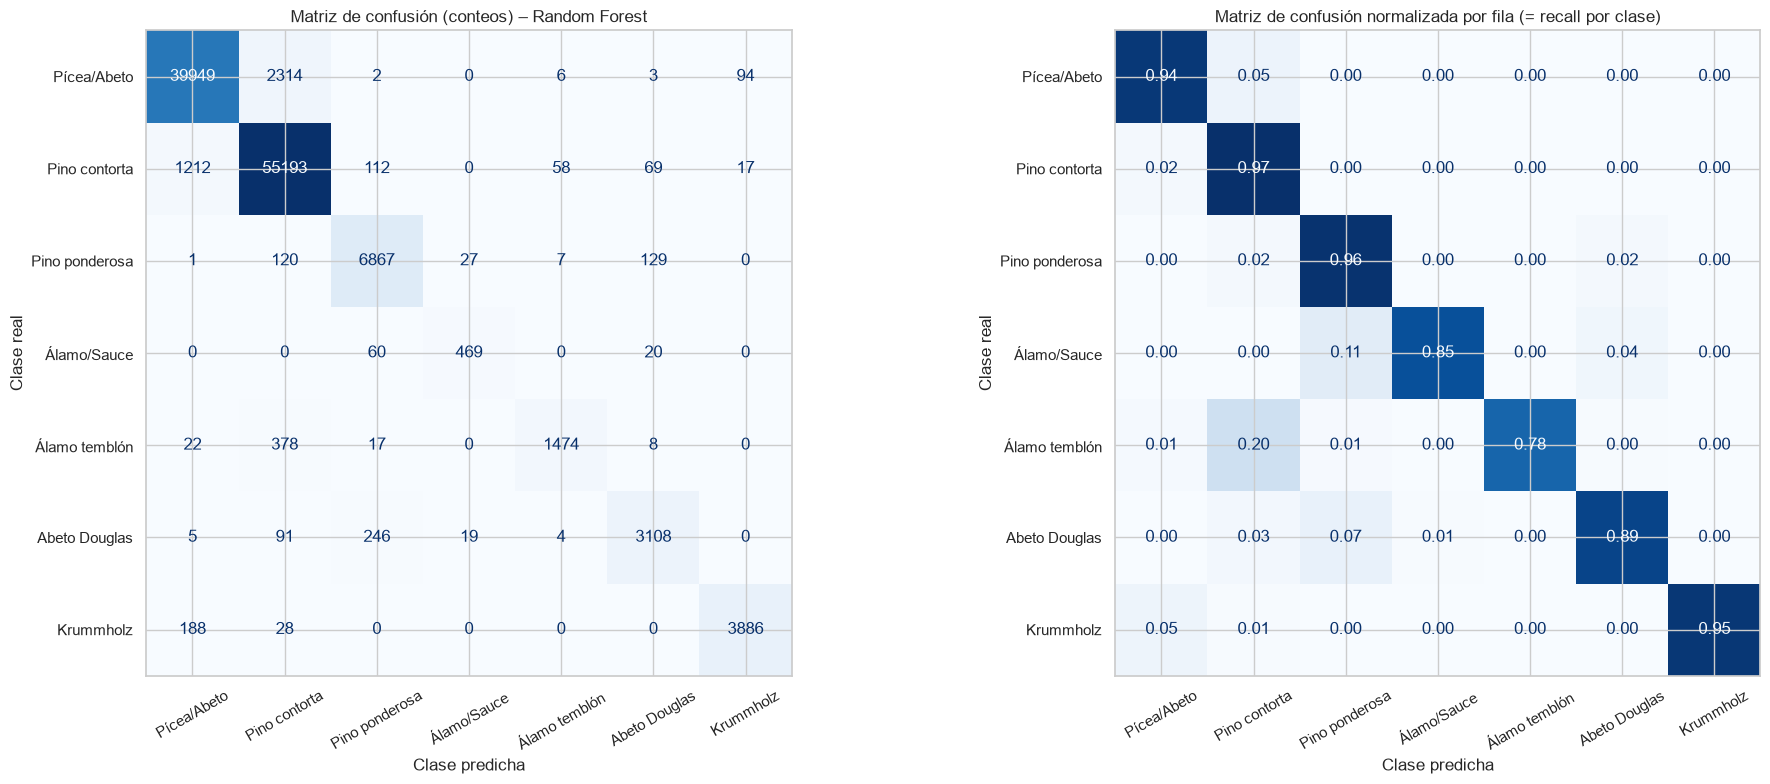

In [20]:
etiquetas = [NOMBRES_CLASE[i] for i in range(1, 8)]
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
cm = confusion_matrix(y_test, y_pred, labels=range(1, 8))
ConfusionMatrixDisplay(cm, display_labels=etiquetas).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title(f"Matriz de confusión (conteos) – {mejor_nombre}")
cm_norm = confusion_matrix(y_test, y_pred, labels=range(1, 8), normalize="true")
ConfusionMatrixDisplay(cm_norm, display_labels=etiquetas).plot(ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
axes[1].set_title("Matriz de confusión normalizada por fila (= recall por clase)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
    ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
plt.tight_layout(); plt.show()

In [21]:
# Principales confusiones (fuera de la diagonal)
cm_df = pd.DataFrame(cm, index=etiquetas, columns=etiquetas)
errores = (cm_df.where(~np.eye(7, dtype=bool)).stack().sort_values(ascending=False).head(6).astype(int)
           .rename("errores").reset_index().rename(columns={"level_0": "real", "level_1": "predicha"}))
errores["% de los errores totales"] = (errores["errores"] / (cm.sum() - np.trace(cm)) * 100).round(1)
errores

,real,predicha,errores,% de los errores totales
0,Pícea/Abeto,Pino contorta,2314,44.0
1,Pino contorta,Pícea/Abeto,1212,23.1
2,Álamo temblón,Pino contorta,378,7.2
3,Abeto Douglas,Pino ponderosa,246,4.7
4,Krummholz,Pícea/Abeto,188,3.6
5,Pino ponderosa,Abeto Douglas,129,2.5


In [22]:
# Comparación con el modelo sin ponderar: recall por clase
rec_rf = recall_score(y_test, predicciones["Random Forest"], average=None)
rec_bal = recall_score(y_test, predicciones["Random Forest (balanced)"], average=None)
rec_log = recall_score(y_test, predicciones["Regresión Logística (escalada)"], average=None)
pd.DataFrame({"Reg. Logística": rec_log, "Random Forest": rec_rf, "RF balanced": rec_bal},
             index=etiquetas).round(4)

,Reg. Logística,Random Forest,RF balanced
Pícea/Abeto,0.6972,0.9429,0.9440
Pino contorta,0.7999,0.9741,0.9745
Pino ponderosa,0.8018,0.9603,0.9600
Álamo/Sauce,0.4317,0.8543,0.8452
Álamo temblón,0.0058,0.7762,0.7899
Abeto Douglas,0.2724,0.8949,0.8848
Krummholz,0.5578,0.9473,0.9500


In [23]:
# Diagnóstico de sobreajuste: desempeño en una muestra de train vs test
idx = np.random.RandomState(SEMILLA).choice(len(X_train), 100_000, replace=False)
acc_train = accuracy_score(y_train.iloc[idx], modelo_final.predict(X_train.iloc[idx]))
print(f"Accuracy train (muestra 100k): {acc_train:.4f} | Accuracy test: {accuracy_score(y_test, y_pred):.4f}")

Accuracy train (muestra 100k): 1.0000 | Accuracy test: 0.9548


## 8. Qué variables manda


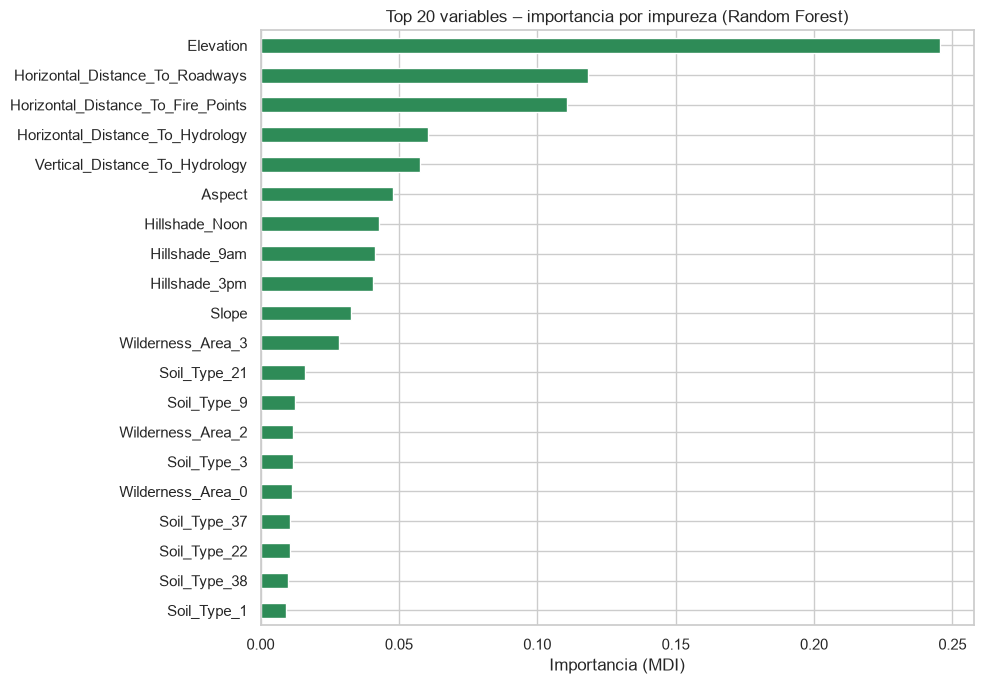

Top 5 variables (MDI): ['Elevation (0.246)', 'Horizontal_Distance_To_Roadways (0.118)', 'Horizontal_Distance_To_Fire_Points (0.111)', 'Horizontal_Distance_To_Hydrology (0.060)', 'Vertical_Distance_To_Hydrology (0.058)']

Importancia agregada por grupo:
Área silvestre (4 one-hot)                 5.7 %
Aspect + Slope                             8.0 %
Sombreado (Hillshade)                     12.5 %
Tipo de suelo (40 one-hot)                14.5 %
Elevation                                 24.6 %
Distancias (agua/carreteras/incendios)    34.7 %
dtype: str


In [24]:
# 8.1 Importancia por reducción de impureza (Gini), propia del Random Forest
rf_imp = modelo_final if hasattr(modelo_final, "feature_importances_") else modelos["Random Forest"]
imp = pd.Series(rf_imp.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
imp.head(20)[::-1].plot(kind="barh", color="seagreen", ax=ax)
ax.set_title("Top 20 variables – importancia por impureza (Random Forest)"); ax.set_xlabel("Importancia (MDI)")
plt.tight_layout(); plt.show()

# Importancia agregada por grupo de variables
grupos = pd.Series({"Elevation": imp["Elevation"],
                    "Distancias (agua/carreteras/incendios)": imp[[c for c in cols_num if "Distance" in c]].sum(),
                    "Sombreado (Hillshade)": imp[[c for c in cols_num if "Hillshade" in c]].sum(),
                    "Aspect + Slope": imp[["Aspect", "Slope"]].sum(),
                    "Tipo de suelo (40 one-hot)": imp[cols_soil].sum(),
                    "Área silvestre (4 one-hot)": imp[cols_wild].sum()}).sort_values()
print("Top 5 variables (MDI):", [f"{k} ({v:.3f})" for k, v in imp.head(5).items()])
print("\nImportancia agregada por grupo:")
print((grupos * 100).round(1).astype(str) + " %")

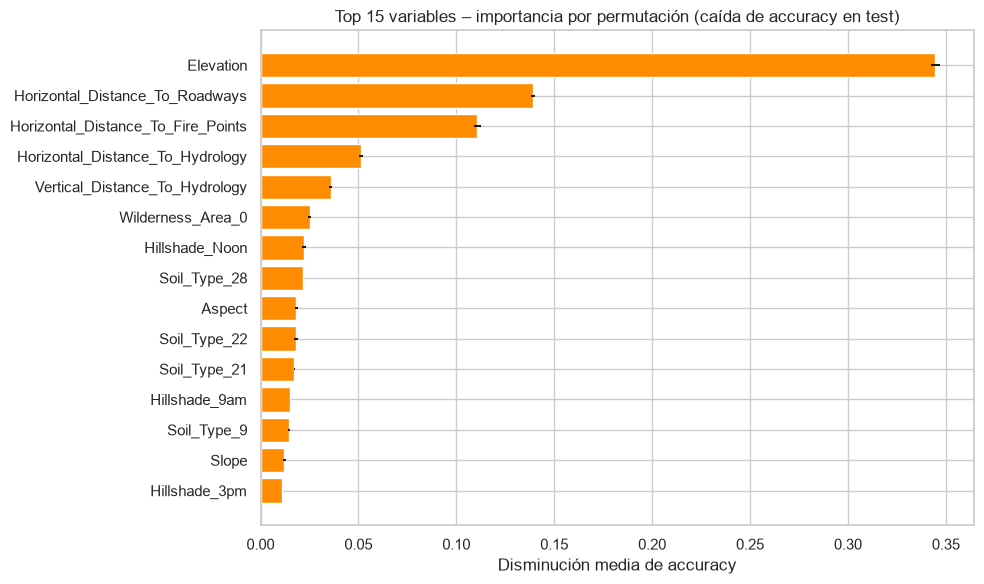

Top 5 variables (permutación): ['Elevation (0.345)', 'Horizontal_Distance_To_Roadways (0.139)', 'Horizontal_Distance_To_Fire_Points (0.111)', 'Horizontal_Distance_To_Hydrology (0.051)', 'Vertical_Distance_To_Hydrology (0.036)']


In [25]:
# 8.2 Importancia por permutación (sobre una muestra del test): mide cuánto cae la accuracy
#     al desordenar cada variable. Es más fiable que MDI (no sesgada hacia variables continuas).
idx_te = np.random.RandomState(SEMILLA).choice(len(X_test), 20_000, replace=False)
perm = permutation_importance(modelo_final, X_test.iloc[idx_te], y_test.iloc[idx_te],
                              n_repeats=3, random_state=SEMILLA, n_jobs=-1, scoring="accuracy")
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
top = perm_imp.head(15)[::-1]
ax.barh(top.index, top.values, xerr=pd.Series(perm.importances_std, index=X.columns)[top.index], color="darkorange")
ax.set_title("Top 15 variables – importancia por permutación (caída de accuracy en test)")
ax.set_xlabel("Disminución media de accuracy")
plt.tight_layout(); plt.show()
print("Top 5 variables (permutación):", [f"{k} ({v:.3f})" for k, v in perm_imp.head(5).items()])

## 9. Lectura crítica de los resultados


In [26]:
# Resumen numérico que se usa en la interpretación
acc_final = accuracy_score(y_test, y_pred)
acc_dummy = tabla_resultados.loc["Dummy (clase mayoritaria)", "accuracy"]
acc_log = tabla_resultados.loc["Regresión Logística (escalada)", "accuracy"]
print(f"Modelo final: {mejor_nombre}")
print(f"Accuracy final {acc_final:.4f} vs Dummy {acc_dummy:.4f} (+{(acc_final-acc_dummy)*100:.1f} pp) "
      f"vs Logística {acc_log:.4f} (+{(acc_final-acc_log)*100:.1f} pp)")
print(f"F1 macro final: {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"Errores totales en test: {int(cm.sum()-np.trace(cm)):,} de {int(cm.sum()):,}")

Modelo final: Random Forest
Accuracy final 0.9548 vs Dummy 0.4876 (+46.7 pp) vs Logística 0.7235 (+23.1 pp)
F1 macro final: 0.9250
Errores totales en test: 5,257 de 116,203


### 9.1 Qué significa cada métrica

- **Accuracy (≈0,95):** el modelo acierta el tipo de bosque en unas 95 de cada 100 parcelas que **nunca vio** durante el entrenamiento. El *baseline* Dummy, que siempre predice "Pino contorta", solo llega a ≈0,49; la Regresión Logística, a ≈0,72; y HistGradientBoosting, a ≈0,88. El salto es enorme y confirma que el problema es **fuertemente no lineal**, y que en este dataset los árboles profundos del Random Forest (que capturan patrones locales muy finos) superan al boosting con la configuración usada.
- **Precision macro alta (≈0,95):** cuando el modelo asigna una clase, casi siempre acierta, incluso en las clases pequeñas.
- **Recall macro algo menor (≈0,91):** en las clases minoritarias (sobre todo *Álamo temblón* y *Abeto Douglas*) se escapan más ejemplos (falsos negativos), porque el modelo tiende a asignarlos a las clases vecinas más frecuentes.
- **F1 macro (≈0,92) frente a F1 ponderado (≈0,95):** la diferencia es la huella del desbalance: el desempeño es excelente en las clases grandes y algo inferior en las pequeñas. Por eso el F1 macro se usó como criterio de selección.

### 9.2 Lo que revela la matriz de confusión

- La diagonal concentra casi todas las predicciones.
- La **mayor fuente de error** es la confusión mutua **Pícea/Abeto → Pino contorta**: son las dos clases mayoritarias y conviven en rangos de altitud solapados (≈2.900-3.200 m), así que comparten condiciones cartográficas.
- Un segundo bloque de confusiones ocurre entre **Pino ponderosa → Abeto Douglas → Álamo/Sauce**, especies de zonas bajas del área silvestre 3.
- *Álamo temblón* tiende a confundirse con *Pino contorta*.
- Ponderar las clases (`class_weight`) desplaza ligeramente la frontera a favor de las minoritarias; la tabla de recall por clase muestra el efecto real sobre cada especie.

### 9.3 Qué variables importan

- **`Elevation` es, con diferencia, la más importante** en los dos métodos (impureza y permutación): la vegetación de montaña está marcada sobre todo por la altitud (temperatura y humedad).
- Le siguen las **distancias horizontales a carreteras y a puntos de incendio**, que actúan como *proxies* de ubicación geográfica y de historial de perturbaciones.
- El **área silvestre** y algunos **tipos de suelo** específicos aportan información categórica clave para separar las especies de zonas bajas.
- Las variables de sombreado, orientación y pendiente tienen importancia moderada o baja de forma individual.

### 9.4 Errores posibles y limitaciones

1. **Autocorrelación espacial / fuga de información geográfica:** las parcelas vecinas son muy parecidas y el reparto aleatorio mete parcelas contiguas en train y en test. Las distancias absolutas funcionan casi como coordenadas, así que el modelo puede estar "memorizando" zonas. El rendimiento real en **un bosque distinto** sería menor; una validación más honesta usaría **particiones espaciales** (por ejemplo, dejar un área silvestre entera fuera).
2. **Desbalance:** las clases 4 (0,5 %) y 5 (1,6 %) tienen muy pocos ejemplos; sus métricas tienen más varianza y su recall es menor.
3. **Sesgo de la importancia MDI:** favorece variables continuas con muchos valores posibles; por eso se complementa con la importancia por permutación. Ninguna de las dos implica **causalidad**.
4. **Representatividad:** los datos provienen de 4 áreas protegidas de Colorado con mínima intervención humana; el modelo no se debe extrapolar a otras regiones o climas sin reentrenar.
5. **Antigüedad y etiquetado:** los datos son de los años 90 y la etiqueta es la especie dominante según el USFS; puede haber cambios (incendios, cambio climático) y ruido en las etiquetas.
6. **Hiperparámetros:** no se hizo una búsqueda exhaustiva (GridSearch o validación cruzada) por coste computacional; un ajuste fino podría mejorar 1-2 puntos porcentuales.
7. **Coste del modelo:** un Random Forest de 150 árboles profundos ocupa bastante memoria y es más lento de inferir que un modelo lineal.
8. **Ligero sobreajuste:** la accuracy en train es ≈1,00 frente a ≈0,95 en test; es típico de un RF sin poda y no impide generalizar, pero deja margen para regularizar (`min_samples_leaf`, `max_depth`).

## 10. Conclusiones

1. Se resolvió un problema de **clasificación multiclase supervisada** con un dataset **real de 581.012 registros** (Covertype, UCI), descargado sin autenticación.
2. Los datos no tenían nulos ni duplicados; las variables categóricas ya estaban codificadas en one-hot y se verificó su coherencia. El **desbalance** (≈103:1) se abordó con partición **estratificada**, métricas **macro** y una variante con **ponderación de clases**.
3. Los modelos basados en árboles superan con creces a los *baselines*: de ≈0,49 (Dummy) y ≈0,72 (Regresión Logística) a ≈0,88 con HistGradientBoosting y **≈0,955 de accuracy** con **Random Forest**, lo que demuestra que las relaciones entre topografía y especie son no lineales y con interacciones.
4. La **altitud** es el factor dominante, seguida de las distancias a carreteras e incendios, el área silvestre y el tipo de suelo, lo cual es coherente con el conocimiento ecológico.
5. Los errores restantes se concentran entre especies que comparten hábitat (Pícea/Abeto → Pino contorta, y las especies de zonas bajas).
6. **Continuación posible:** validación espacial (dejando fuera un área silvestre), búsqueda de hiperparámetros con validación cruzada, probar XGBoost/LightGBM y	aadir *feature engineering* (distancia euclidiana al agua, interacciones altitud-suelo).
